In [ ]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.interpolate import splprep, splev

try:
    from skimage.exposure import rescale_intensity
    from skimage.filters import gaussian
    from skimage.segmentation import active_contour
except ImportError as exc:
    raise ImportError(
        "This notebook requires scikit-image in the current kernel. Install it with `pip install scikit-image`."
    ) from exc

data_dir = Path.cwd()
#TODO: create a new data input for each file
# DATA_INPUT = "PBS" 
# DATA_INPUT = "FN"
DATA_INPUT = "FN TOP"
pbs_image_path = data_dir / "PBS 3-MaxIP_with brigthfield.tif"
pbs_polyline_path = data_dir / "PBS3_Brightfield_Frame1_Boundary_XY_Coordinates.csv"
pbs_spots_path = data_dir / "PBS 3-MaxIP_segmented_spots.csv"
fn_image_path = data_dir / "FN 3-MaxIP.tif"
fn_polyline_path = data_dir / "FN3_OriginFrame_XY_Coordinates.csv"
fn_top_polyline_path = data_dir / "XY_Coordinates_top.csv"
fn_spots_path = data_dir / "FN 3-MaxIP_spots.csv"
# ALLESSANDRA TODO: CREATE A IMAGE PATH POLYLINE PATH AND SPOTS PATH
if DATA_INPUT == "PBS":
    image_path = pbs_image_path
    polyline_path = pbs_polyline_path
    spots_path = pbs_spots_path
elif DATA_INPUT == "FN":
    image_path = fn_image_path
    polyline_path = fn_polyline_path
    spots_path = fn_spots_path
# TODO ALLESSANDRA: CREATE a new elif statement like the above
elif DATA_INPUT == "FN TOP":
    image_path = fn_image_path
    polyline_path = fn_top_polyline_path
    spots_path = fn_spots_path
else:
    raise NotImplementedError


def parse_imagej_description(text):
    metadata = {}
    for line in text.splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            metadata[key.strip()] = value.strip()
    return metadata


def page_index(channel_idx, time_idx, n_channels):
    return time_idx * n_channels + channel_idx


def load_channel_frame(image_path, channel_idx, time_idx, n_channels):
    with Image.open(image_path) as tif:
        tif.seek(page_index(channel_idx, time_idx, n_channels))
        return np.asarray(tif, dtype=np.float32)


def normalize_for_display(image, vmin=None, vmax=None, lower_percentile=1, upper_percentile=99.5):
    source = image[image > 0]
    if source.size == 0:
        source = image.ravel()

    if vmin is None:
        vmin = float(np.percentile(source, lower_percentile))
    if vmax is None:
        vmax = float(np.percentile(source, upper_percentile))
    if vmax <= vmin:
        vmax = vmin + 1.0

    scaled = np.clip((image - vmin) / (vmax - vmin), 0, 1)
    return scaled, float(vmin), float(vmax)


def preprocess_snake_source(source_image):
    source_nonzero = source_image[source_image > 0]
    source_intensity_range = (
        float(np.percentile(source_nonzero, 1)) if source_nonzero.size else float(source_image.min()),
        float(np.percentile(source_nonzero, 99.5)) if source_nonzero.size else float(source_image.max()),
    )
    snake_ready = rescale_intensity(source_image, in_range=source_intensity_range, out_range=(0.0, 1.0))
    snake_ready = gaussian(snake_ready, sigma=2.0, preserve_range=True)
    return snake_ready


def resample_open_polyline(points_xy, n_points=300, smoothing=0.0):
    tck, _ = splprep([points_xy[:, 0], points_xy[:, 1]], s=smoothing, per=False)
    u = np.linspace(0, 1, n_points, endpoint=True)
    x_new, y_new = splev(u, tck)
    return np.column_stack([x_new, y_new])


with Image.open(image_path) as tif:
    imagej_metadata = parse_imagej_description(str(tif.tag_v2.get(270, "")))
    n_pages = getattr(tif, "n_frames", 1)
    n_channels = int(imagej_metadata.get("channels", 1))
    n_timepoints = int(imagej_metadata.get("frames", max(1, n_pages // max(n_channels, 1))))

    channel_images_t0 = []
    for channel_idx in range(n_channels):
        tif.seek(page_index(channel_idx, 0, n_channels))
        channel_images_t0.append(np.asarray(tif, dtype=np.float32))

channel_images_t0 = np.stack(channel_images_t0, axis=0)
handdrawn_polyline = pd.read_csv(polyline_path)
polyline_xy = handdrawn_polyline[["X", "Y"]].to_numpy(dtype=float)
open_snake_boundary_condition = "free"
initial_snake_xy = resample_open_polyline(polyline_xy, n_points=400, smoothing=0.0)
initial_snake_rc = np.column_stack([initial_snake_xy[:, 1], initial_snake_xy[:, 0]])

# Leave this empty for percentile-based display, or set per-channel FIJI windows like {0: (42, 675)}.
manual_display_windows = {}

channel_display_images = []
channel_display_ranges = []
channel_stats_rows = []

for channel_idx, image in enumerate(channel_images_t0):
    override = manual_display_windows.get(channel_idx)
    if override is None:
        display_image, display_min, display_max = normalize_for_display(image)
    else:
        display_image, display_min, display_max = normalize_for_display(image, *override)

    nonzero = image[image > 0]
    source = nonzero if nonzero.size else image.ravel()
    channel_display_images.append(display_image)
    channel_display_ranges.append((display_min, display_max))
    channel_stats_rows.append(
        {
            "channel": channel_idx,
            "mean_intensity": float(image.mean()),
            "median_intensity": float(np.median(source)),
            "nonzero_fraction": float(np.count_nonzero(image) / image.size),
            "display_min": display_min,
            "display_max": display_max,
        }
    )

channel_display_images = np.stack(channel_display_images, axis=0)
channel_stats = pd.DataFrame(channel_stats_rows).set_index("channel")

# The brightfield / transmitted-light plane is usually the channel with the broader, brighter baseline.
snake_channel_index = int(channel_stats["median_intensity"].idxmax())

if n_channels == 2:
    fluorescence_channel_index = 1 - snake_channel_index
else:
    fluorescence_channel_index = 0

brightfield_display = channel_display_images[snake_channel_index]
fluorescence_display = channel_display_images[fluorescence_channel_index]
composite_rgb = np.dstack(
    [
        np.clip(0.9 * brightfield_display, 0, 1),
        np.clip(0.9 * brightfield_display + fluorescence_display, 0, 1),
        np.clip(0.9 * brightfield_display, 0, 1),
    ]
)

snake_source = channel_images_t0[snake_channel_index]
snake_image = preprocess_snake_source(snake_source)

# ALLESSANDRA TODO: potentially change the contour parameterisation, but try these first
'''    Parameters
    ----------

    beta : float, optional
        Snake smoothness shape parameter. Higher values makes snake smoother.
    w_line : float, optional
        Controls attraction to brightness. Use negative values to attract
        toward dark regions.
    w_edge : float, optional
        Controls attraction to edges. Use negative values to repel snake from
        edges.
    max_num_iter : int, optional
        Maximum iterations to optimize snake shape.
    convergence : float, optional
        Convergence criteria.
    boundary_condition : str, optional
        Boundary conditions for the contour. Can be one of 'periodic',
        'free', 'fixed', 'free-fixed', or 'fixed-free'. 'periodic' attaches
        the two ends of the snake, 'fixed' holds the end-points in place,
        and 'free' allows free movement of the ends. 'fixed' and 'free' can
        be combined by parsing 'fixed-free', 'free-fixed'. Parsing
        'fixed-fixed' or 'free-free' yields same behaviour as 'fixed' and
        'free', respectively.'''

pbs_snake_active_contour_kwargs = dict(
    beta=0.01,
    w_line=4.0,
    w_edge=2.0,
    max_num_iter=2500,
    convergence=0.01,
    boundary_condition=open_snake_boundary_condition,
)
fn_snake_active_contour_kwargs = dict(
    beta = 0.01,
    w_line = 0.0,
    w_edge = 2.0,
    max_num_iter=2500,
    convergence=0.01,
    boundary_condition=open_snake_boundary_condition,
)
if DATA_INPUT == "PBS":
    snake_active_contour_kwargs = pbs_snake_active_contour_kwargs
elif DATA_INPUT == "FN":
    snake_active_contour_kwargs = fn_snake_active_contour_kwargs

if DATA_INPUT == "PBS":
    dynamic_anchor_frame_interval = 50
elif DATA_INPUT == "FN":
    dynamic_anchor_frame_interval = 1
use_dynamic_contour_cache = True
dynamic_contour_cache_dir = data_dir / "dynamic_contour_cache"


def build_dynamic_anchor_frames(n_timepoints, frame_interval):
    if frame_interval <= 0:
        raise ValueError("`frame_interval` must be a positive integer.")
    if n_timepoints <= 0:
        raise ValueError("`n_timepoints` must be positive.")

    # Match the previous convention: interval 50 means frames 0, 49, 99, ... in 0-based CSV coordinates.
    interval_anchor_frames = np.arange(frame_interval - 1, n_timepoints, frame_interval, dtype=int)
    anchor_frames = np.unique(np.r_[0, interval_anchor_frames, n_timepoints - 1]).astype(int)
    return anchor_frames


def file_fingerprint(path):
    path = Path(path)
    stat = path.stat()
    return {
        "name": path.name,
        "path": str(path.resolve()),
        "size": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
    }


def json_ready(value):
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(key): json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(item) for item in value]
    return value


def build_dynamic_contour_cache_metadata():
    return json_ready(
        {
            "data_input": DATA_INPUT,
            "image": file_fingerprint(image_path),
            "polyline": file_fingerprint(polyline_path),
            "snake_channel_index": snake_channel_index,
            "n_channels": n_channels,
            "n_timepoints": n_timepoints,
            "dynamic_anchor_frame_interval": dynamic_anchor_frame_interval,
            "dynamic_anchor_frames": dynamic_anchor_frames,
            "active_contour_kwargs": snake_active_contour_kwargs,
            "initial_snake_point_count": len(initial_snake_xy),
        }
    )


def dynamic_contour_cache_path(cache_dir, metadata):
    metadata_json = json.dumps(metadata, sort_keys=True)
    metadata_hash = hashlib.sha256(metadata_json.encode("utf-8")).hexdigest()[:16]
    image_stem = Path(metadata["image"]["name"]).stem
    safe_stem = "".join(char if char.isalnum() else "_" for char in image_stem).strip("_")
    return Path(cache_dir) / f"{safe_stem}_dynamic_contours_{metadata_hash}.npz"

TESTING_MODE = False
if TESTING_MODE == False:
    dynamic_anchor_frames = build_dynamic_anchor_frames(n_timepoints, dynamic_anchor_frame_interval)
else:
    n_timepoints = 5
    dynamic_anchor_frame_interval = 1
    dynamic_anchor_frames = build_dynamic_anchor_frames(n_timepoints, dynamic_anchor_frame_interval)

print(f"ImageJ reports {n_channels} channel(s), {n_timepoints} timepoint(s), and {n_pages} TIFF pages.")
print(f"Selected channel {snake_channel_index} for the active contour; override `snake_channel_index` if FIJI shows a different brightfield order.")
print(
    "Using an open initial spline. Set `open_snake_boundary_condition` to 'fixed' to pin both endpoints, "
    "or use 'free-fixed' / 'fixed-free' to pin only one end."
)
print(f"Dynamic anchor frame interval: every {dynamic_anchor_frame_interval} frame(s)")
print(f"Dynamic anchor frames (0-based CSV Frame values): {dynamic_anchor_frames.tolist()}")
channel_stats


ImageJ reports 2 channel(s), 289 timepoint(s), and 578 TIFF pages.
Selected channel 1 for the active contour; override `snake_channel_index` if FIJI shows a different brightfield order.
Using an open initial spline. Set `open_snake_boundary_condition` to 'fixed' to pin both endpoints, or use 'free-fixed' / 'fixed-free' to pin only one end.
Dynamic anchor frame interval: every 1 frame(s)
Dynamic anchor frames (0-based CSV Frame values): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133,

,mean_intensity,median_intensity,nonzero_fraction,display_min,display_max
channel,,,,,
0,103.752327,99.0,1.0,69.0,209.0
1,131.915741,122.0,1.0,98.0,204.0


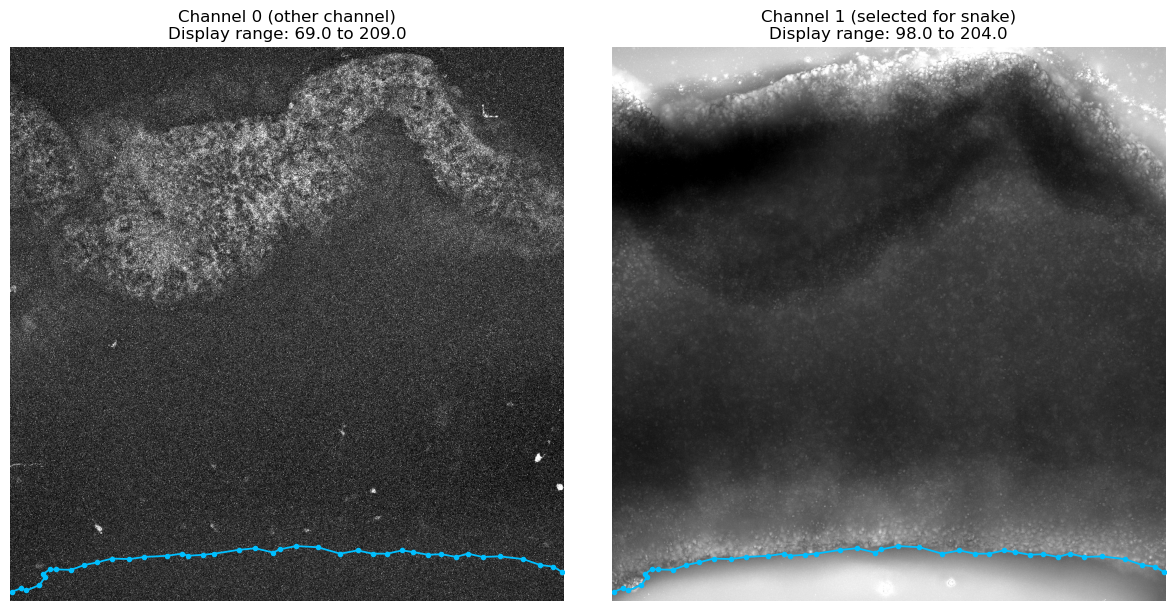

In [16]:
fig, axes = plt.subplots(1, n_channels, figsize=(6 * n_channels, 6), constrained_layout=True)
axes = np.atleast_1d(axes)

for channel_idx, ax in enumerate(axes):
    display_min, display_max = channel_display_ranges[channel_idx]
    role = "selected for snake" if channel_idx == snake_channel_index else "other channel"
    ax.imshow(channel_images_t0[channel_idx], cmap="gray", vmin=display_min, vmax=display_max)
    ax.plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="deepskyblue", linewidth=1.3, markersize=3)
    ax.set_title(f"Channel {channel_idx} ({role})\nDisplay range: {display_min:.1f} to {display_max:.1f}")
    ax.set_axis_off()

plt.show()


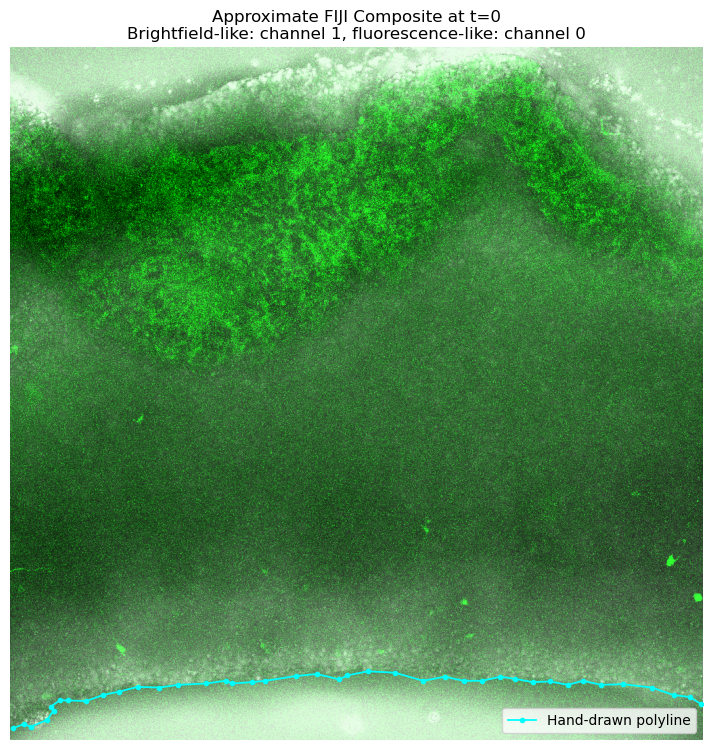

In [17]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(composite_rgb)
ax.plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="cyan", linewidth=1.3, markersize=3, label="Hand-drawn polyline")
ax.set_title(
    f"Approximate FIJI Composite at t=0\nBrightfield-like: channel {snake_channel_index}, fluorescence-like: channel {fluorescence_channel_index}"
)
ax.set_axis_off()
ax.legend(loc="lower right")
plt.show()


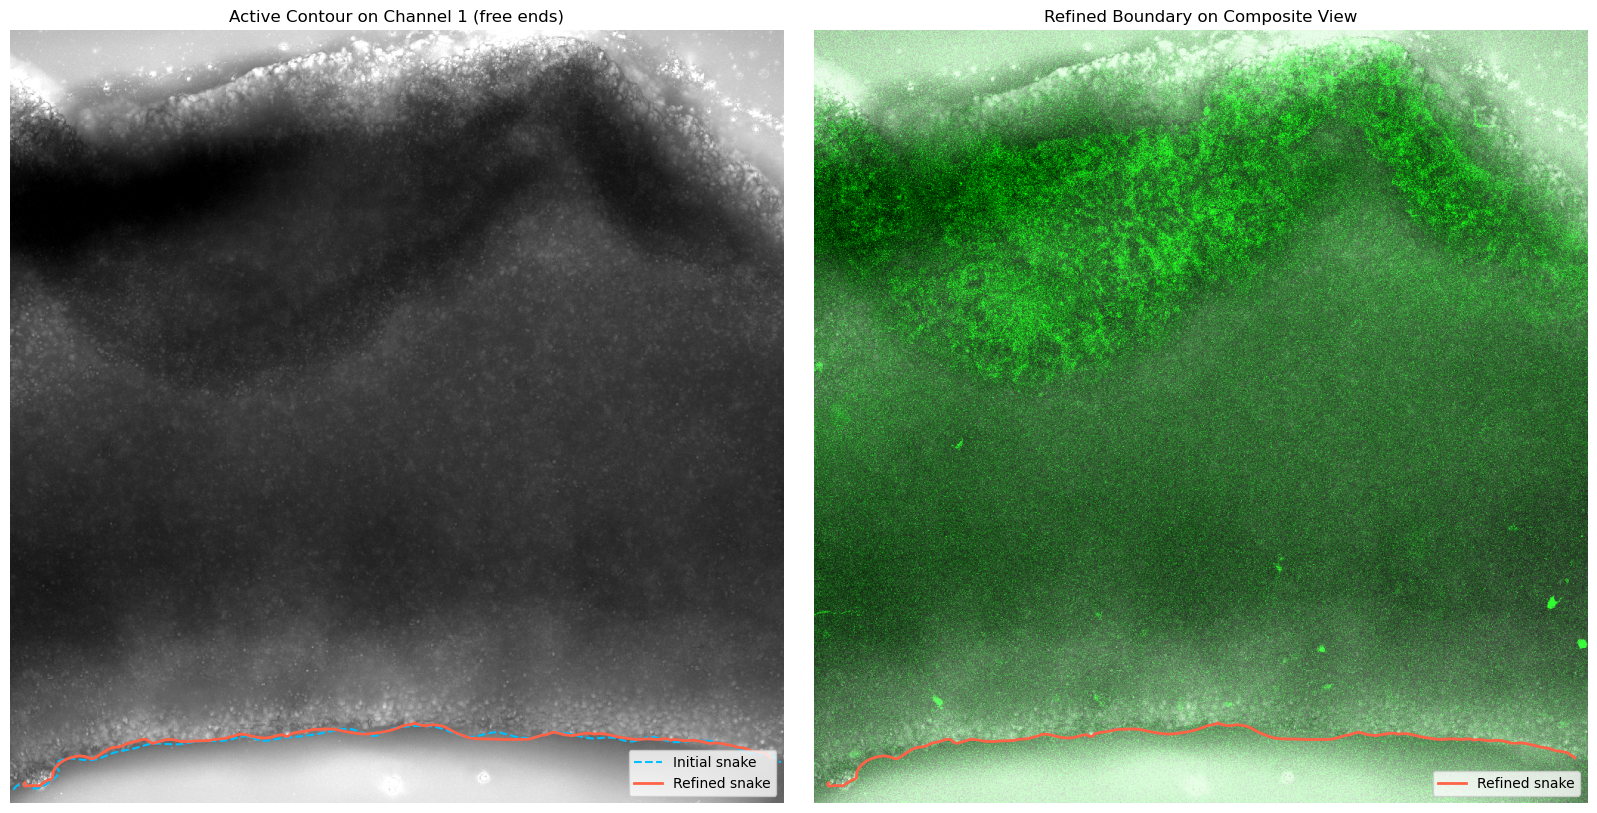

,X,Y
0,19.186556,996.522095
1,18.836666,997.012695
2,18.482025,997.532959
3,18.121279,998.071655
4,17.826199,998.816772


In [18]:
# Static baseline: refine the contour on the first frame only.
refined_snake_rc = active_contour(
    snake_image,
    initial_snake_rc,
    **snake_active_contour_kwargs,
)

refined_snake_xy = np.column_stack([refined_snake_rc[:, 1], refined_snake_rc[:, 0]])
refined_polyline = pd.DataFrame(refined_snake_xy, columns=["X", "Y"])

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

display_min, display_max = channel_display_ranges[snake_channel_index]
axes[0].imshow(channel_images_t0[snake_channel_index], cmap="gray", vmin=display_min, vmax=display_max)
axes[0].plot(initial_snake_xy[:, 0], initial_snake_xy[:, 1], "--", color="deepskyblue", linewidth=1.5, label="Initial snake")
axes[0].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0, label="Refined snake")
axes[0].set_title(f"Active Contour on Channel {snake_channel_index} ({open_snake_boundary_condition} ends)")
axes[0].set_axis_off()
axes[0].legend(loc="lower right")

axes[1].imshow(composite_rgb)
axes[1].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0, label="Refined snake")
axes[1].set_title("Refined Boundary on Composite View")
axes[1].set_axis_off()
axes[1].legend(loc="lower right")

plt.show()
refined_polyline.head()


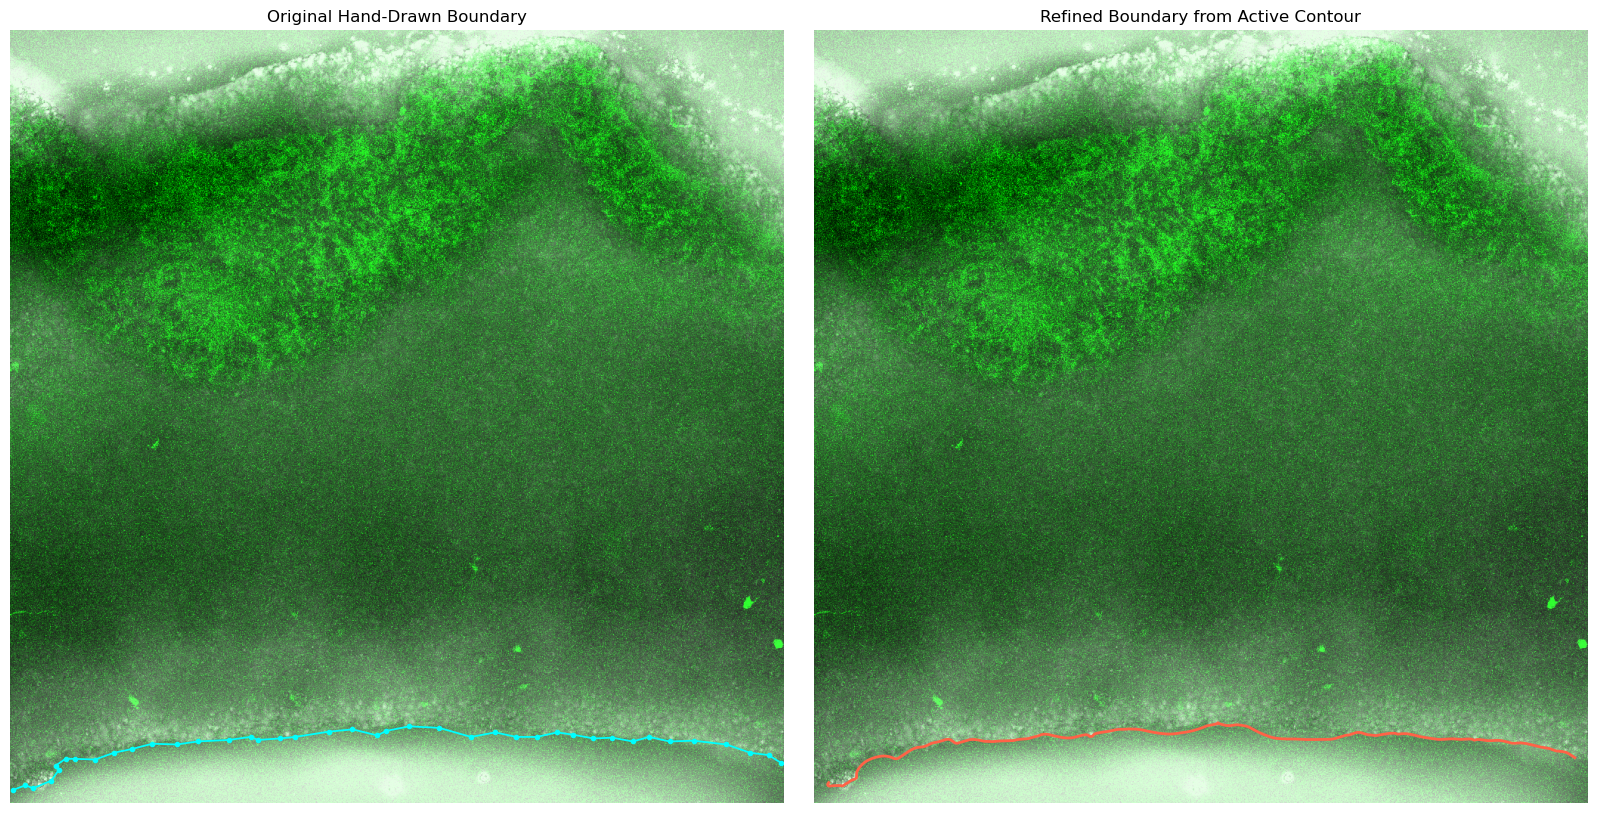

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

axes[0].imshow(composite_rgb)
axes[0].plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="cyan", linewidth=1.3, markersize=3)
axes[0].set_title("Original Hand-Drawn Boundary")
axes[0].set_axis_off()

axes[1].imshow(composite_rgb)
axes[1].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0)
axes[1].set_title("Refined Boundary from Active Contour")
axes[1].set_axis_off()

plt.show()


In [12]:
df_spots = pd.read_csv(spots_path, skiprows=[1, 2, 3])


def prepare_curve(curve_xy):
    curve = np.asarray(curve_xy, dtype=float).copy()

    if len(curve) < 2:
        raise ValueError("The boundary polyline needs at least two points.")

    segment_steps = np.linalg.norm(np.diff(curve, axis=0), axis=1)
    curve = curve[np.r_[True, segment_steps > 0]]

    if len(curve) < 2:
        raise ValueError("The boundary polyline collapses to fewer than two unique points.")

    segment_vectors = np.diff(curve, axis=0)
    segment_lengths = np.linalg.norm(segment_vectors, axis=1)
    arc_lengths = np.concatenate([[0.0], np.cumsum(segment_lengths)])
    return curve, arc_lengths


def build_curve_cache(curve_xy):
    curve, arc_lengths = prepare_curve(curve_xy)
    return {"curve": curve, "arc_lengths": arc_lengths}


def point_to_segment(p, a, b):
    ab = b - a
    ab2 = np.dot(ab, ab)
    if ab2 == 0:
        return a.copy(), 0.0

    t = np.dot(p - a, ab) / ab2
    t = np.clip(t, 0.0, 1.0)
    closest = a + t * ab
    return closest, t


def stable_segment_tangent(curve, segment_index, half_window=8, min_span=5.0):
    left = max(0, segment_index - half_window)
    right = min(len(curve) - 1, segment_index + 1 + half_window)

    while True:
        tangent = curve[right] - curve[left]
        tangent_length = np.linalg.norm(tangent)
        if tangent_length >= min_span:
            return tangent / tangent_length

        can_expand_left = left > 0
        can_expand_right = right < len(curve) - 1
        if not can_expand_left and not can_expand_right:
            break
        if can_expand_left:
            left -= 1
        if can_expand_right:
            right += 1

    # Fallback for very short curves: use the nearest non-zero local segment.
    for offset in range(len(curve) - 1):
        for candidate_index in (segment_index - offset, segment_index + offset):
            if 0 <= candidate_index < len(curve) - 1:
                tangent = curve[candidate_index + 1] - curve[candidate_index]
                tangent_length = np.linalg.norm(tangent)
                if tangent_length > 0:
                    return tangent / tangent_length

    raise ValueError("The boundary polyline has no non-zero tangent.")


def signed_distance_to_polyline(p, curve, arc_lengths):
    best_dist2 = np.inf
    best_closest = None
    best_segment_index = None
    best_t = None

    for i in range(len(curve) - 1):
        a, b = curve[i], curve[i + 1]
        closest, t = point_to_segment(p, a, b)
        diff = p - closest
        dist2 = np.dot(diff, diff)

        if dist2 < best_dist2:
            best_dist2 = dist2
            best_closest = closest
            best_segment_index = i
            best_t = t

    a = curve[best_segment_index]
    b = curve[best_segment_index + 1]
    tangent = stable_segment_tangent(curve, best_segment_index)
    normal = np.array([-tangent[1], tangent[0]])

    offset = p - best_closest
    dot = np.dot(offset, normal)
    sign = -1.0 if dot > 0 else 1.0 if dot < 0 else 0.0

    signed_distance = sign * np.sqrt(best_dist2)
    s = arc_lengths[best_segment_index] + best_t * np.linalg.norm(b - a)
    return signed_distance, best_closest, best_segment_index, s


def measure_points_against_curve(points_xy, curve_cache):
    if len(points_xy) == 0:
        return np.empty((0, 4), dtype=object)

    return np.array(
        [signed_distance_to_polyline(p, curve_cache["curve"], curve_cache["arc_lengths"]) for p in points_xy],
        dtype=object,
    )


static_curve_cache = build_curve_cache(refined_snake_xy)
static_curve = static_curve_cache["curve"]
spot_xy = df_spots[["X", "Y"]].to_numpy(dtype=float)

static_results = measure_points_against_curve(spot_xy, static_curve_cache)
static_closest_boundary_xy = np.vstack(static_results[:, 1])

df_spots["signed_distance_to_boundary"] = static_results[:, 0].astype(float)
df_spots["closest_boundary_x"] = static_closest_boundary_xy[:, 0]
df_spots["closest_boundary_y"] = static_closest_boundary_xy[:, 1]
df_spots["closest_boundary_segment"] = static_results[:, 2].astype(int)
df_spots["boundary_arc_length"] = static_results[:, 3].astype(float)

# If the sign is flipped relative to your biological convention, reverse `static_curve`
# or multiply `signed_distance_to_boundary` by -1 after inspecting a few points.
df_spots[["Spot ID", "Frame", "X", "Y", "signed_distance_to_boundary", "boundary_arc_length"]].head()


,Spot ID,Frame,X,Y,signed_distance_to_boundary,boundary_arc_length
0,4545,26,866.458764,672.516245,266.208075,895.387304
1,3522,23,867.426427,674.794173,263.929030,895.387304
2,3587,13,865.500080,684.190327,254.538831,895.387304
3,3459,18,866.669721,679.065973,259.657819,895.387304
4,3588,6,865.492455,693.173454,245.555979,895.387304


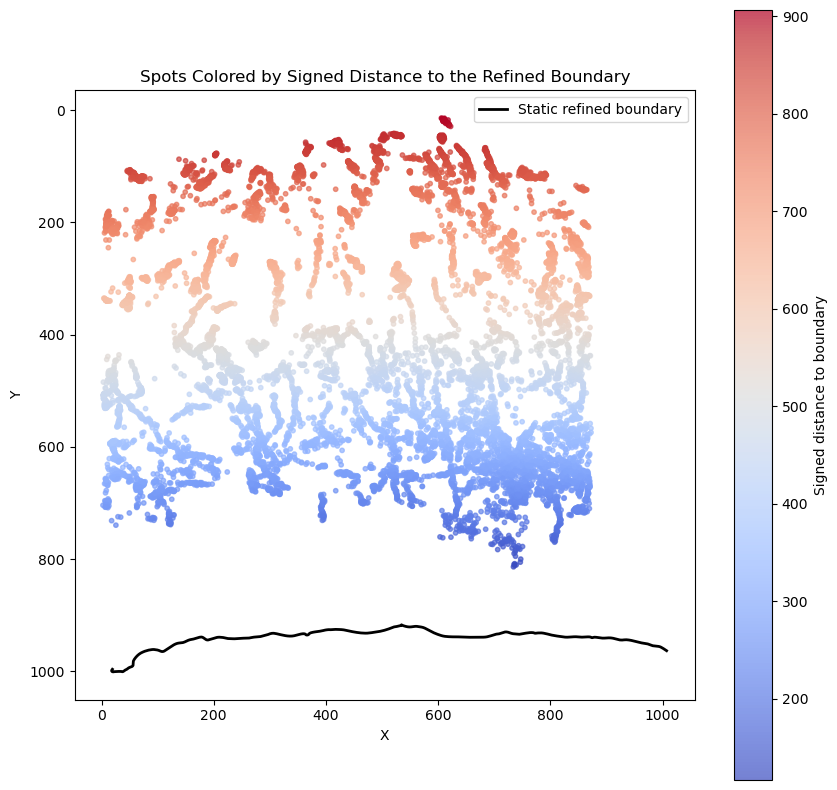

In [13]:
fig, ax = plt.subplots(figsize=(10, 10))
scatter = ax.scatter(
    df_spots["X"],
    df_spots["Y"],
    c=df_spots["signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
)
ax.plot(static_curve[:, 0], static_curve[:, 1], color="black", linewidth=2.0, label="Static refined boundary")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_title("Spots Colored by Signed Distance to the Refined Boundary")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend(loc="best")
plt.colorbar(scatter, ax=ax, label="Signed distance to boundary")
plt.show()


In [14]:

def assign_dynamic_anchor_frame(frame_value, anchor_frames):
    diffs = np.abs(anchor_frames - frame_value)
    min_diff = diffs.min()
    # Later-anchor tie breaking: if two anchors are equally close, choose the later one.
    return int(anchor_frames[diffs == min_diff][-1])


def load_dynamic_anchor_curves_from_cache(cache_path, expected_anchor_frames):
    if not Path(cache_path).exists():
        return None

    with np.load(cache_path, allow_pickle=False) as cached:
        cached_anchor_frames = cached["anchor_frames"].astype(int)
        if not np.array_equal(cached_anchor_frames, expected_anchor_frames):
            return None
        cached_curves = cached["curves"].astype(float)

    return {int(anchor_frame): cached_curves[index].copy() for index, anchor_frame in enumerate(cached_anchor_frames)}


def save_dynamic_anchor_curves_to_cache(cache_path, metadata, anchor_frames, anchor_curves):
    cache_path = Path(cache_path)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    curves = np.stack([anchor_curves[int(anchor_frame)] for anchor_frame in anchor_frames], axis=0)
    np.savez_compressed(
        cache_path,
        anchor_frames=np.asarray(anchor_frames, dtype=int),
        curves=curves,
        metadata_json=np.array(json.dumps(metadata, sort_keys=True)),
    )


dynamic_contour_cache_metadata = build_dynamic_contour_cache_metadata()
dynamic_contour_cache_file = dynamic_contour_cache_path(dynamic_contour_cache_dir, dynamic_contour_cache_metadata)
cached_dynamic_anchor_curves = None

if use_dynamic_contour_cache:
    cached_dynamic_anchor_curves = load_dynamic_anchor_curves_from_cache(dynamic_contour_cache_file, dynamic_anchor_frames)

if cached_dynamic_anchor_curves is not None:
    dynamic_anchor_curves = cached_dynamic_anchor_curves
    dynamic_anchor_curve_caches = {
        anchor_frame: build_curve_cache(anchor_curve) for anchor_frame, anchor_curve in dynamic_anchor_curves.items()
    }
    print(f"Loaded dynamic anchor contours from cache: {dynamic_contour_cache_file}")
else:
    if use_dynamic_contour_cache:
        print(f"No matching dynamic contour cache found; computing contours for: {image_path.name}")

    dynamic_anchor_curves = {0: refined_snake_xy.copy()}
    dynamic_anchor_curve_caches = {0: build_curve_cache(refined_snake_xy)}
    previous_anchor_snake_rc = refined_snake_rc.copy()

    for anchor_frame in dynamic_anchor_frames[1:]:
        anchor_source = load_channel_frame(image_path, snake_channel_index, anchor_frame, n_channels)
        anchor_image = preprocess_snake_source(anchor_source)
        anchor_snake_rc = active_contour(
            anchor_image,
            previous_anchor_snake_rc,
            **snake_active_contour_kwargs,
        )
        anchor_snake_xy = np.column_stack([anchor_snake_rc[:, 1], anchor_snake_rc[:, 0]])
        dynamic_anchor_curves[anchor_frame] = anchor_snake_xy
        dynamic_anchor_curve_caches[anchor_frame] = build_curve_cache(anchor_snake_xy)
        previous_anchor_snake_rc = anchor_snake_rc

    if use_dynamic_contour_cache:
        save_dynamic_anchor_curves_to_cache(
            dynamic_contour_cache_file,
            dynamic_contour_cache_metadata,
            dynamic_anchor_frames,
            dynamic_anchor_curves,
        )
        print(f"Saved dynamic anchor contours to cache: {dynamic_contour_cache_file}")

show_dynamic_anchor_contour_overlays = False
dynamic_anchor_overlay_columns = 3

if show_dynamic_anchor_contour_overlays:
    n_anchor_plots = len(dynamic_anchor_frames)
    n_cols = min(dynamic_anchor_overlay_columns, n_anchor_plots)
    n_rows = int(np.ceil(n_anchor_plots / n_cols))
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 5 * n_rows),
        squeeze=False,
        constrained_layout=True,
    )

    for ax, anchor_frame in zip(axes.ravel(), dynamic_anchor_frames):
        anchor_source = load_channel_frame(image_path, snake_channel_index, anchor_frame, n_channels)
        display_image, display_min, display_max = normalize_for_display(anchor_source)
        anchor_curve = dynamic_anchor_curve_caches[anchor_frame]["curve"]

        ax.imshow(anchor_source, cmap="gray", vmin=display_min, vmax=display_max)
        ax.plot(anchor_curve[:, 0], anchor_curve[:, 1], color="tomato", linewidth=1.6)
        ax.set_title(f"Dynamic anchor frame {anchor_frame}")
        ax.set_axis_off()

    for ax in axes.ravel()[n_anchor_plots:]:
        ax.set_visible(False)

    plt.show()

df_spots_dynamic = df_spots.copy()
spot_anchor_frames = np.array(
    [assign_dynamic_anchor_frame(frame_value, dynamic_anchor_frames) for frame_value in df_spots_dynamic["Frame"].to_numpy(dtype=int)],
    dtype=int,
)

dynamic_signed_distance = np.full(len(df_spots_dynamic), np.nan, dtype=float)
dynamic_closest_boundary_xy = np.full((len(df_spots_dynamic), 2), np.nan, dtype=float)
dynamic_closest_boundary_segment = np.full(len(df_spots_dynamic), -1, dtype=int)
dynamic_boundary_arc_length = np.full(len(df_spots_dynamic), np.nan, dtype=float)

for anchor_frame in dynamic_anchor_frames:
    mask = spot_anchor_frames == anchor_frame
    anchor_points = df_spots_dynamic.loc[mask, ["X", "Y"]].to_numpy(dtype=float)
    anchor_results = measure_points_against_curve(anchor_points, dynamic_anchor_curve_caches[anchor_frame])
    if len(anchor_results) == 0:
        continue

    dynamic_signed_distance[mask] = anchor_results[:, 0].astype(float)
    dynamic_closest_boundary_xy[mask] = np.vstack(anchor_results[:, 1])
    dynamic_closest_boundary_segment[mask] = anchor_results[:, 2].astype(int)
    dynamic_boundary_arc_length[mask] = anchor_results[:, 3].astype(float)

df_spots_dynamic["dynamic_anchor_frame"] = spot_anchor_frames
df_spots_dynamic["dynamic_signed_distance_to_boundary"] = dynamic_signed_distance
df_spots_dynamic["dynamic_closest_boundary_x"] = dynamic_closest_boundary_xy[:, 0]
df_spots_dynamic["dynamic_closest_boundary_y"] = dynamic_closest_boundary_xy[:, 1]
df_spots_dynamic["dynamic_closest_boundary_segment"] = dynamic_closest_boundary_segment
df_spots_dynamic["dynamic_boundary_arc_length"] = dynamic_boundary_arc_length

if df_spots_dynamic[
    [
        "dynamic_signed_distance_to_boundary",
        "dynamic_closest_boundary_x",
        "dynamic_closest_boundary_y",
        "dynamic_boundary_arc_length",
    ]
].isna().any().any():
    raise ValueError("Dynamic boundary measurement left missing values in the spot table.")

dynamic_anchor_summary = pd.DataFrame(
    {
        "anchor_frame": dynamic_anchor_frames,
        "contour_point_count": [len(dynamic_anchor_curve_caches[anchor_frame]["curve"]) for anchor_frame in dynamic_anchor_frames],
        "spot_count": [int((spot_anchor_frames == anchor_frame).sum()) for anchor_frame in dynamic_anchor_frames],
    }
)

def build_dynamic_anchor_assignment_check_frames(anchor_frames, n_timepoints):
    check_frames = [0, n_timepoints - 1]
    for left_anchor, right_anchor in zip(anchor_frames[:-1], anchor_frames[1:]):
        midpoint_floor = (left_anchor + right_anchor) // 2
        check_frames.extend([left_anchor, midpoint_floor, min(midpoint_floor + 1, right_anchor), right_anchor])
    return np.array(sorted(set(np.clip(check_frames, 0, n_timepoints - 1))), dtype=int)


dynamic_anchor_assignment_check = pd.DataFrame(
    {"frame": build_dynamic_anchor_assignment_check_frames(dynamic_anchor_frames, n_timepoints)}
)
dynamic_anchor_assignment_check["assigned_anchor_frame"] = dynamic_anchor_assignment_check["frame"].apply(
    lambda frame_value: assign_dynamic_anchor_frame(frame_value, dynamic_anchor_frames)
)

print("Computed dynamic anchor contours:", dynamic_anchor_frames.tolist())
print("Spot-to-anchor assignment checks:")
dynamic_anchor_assignment_check


No matching dynamic contour cache found; computing contours for: FN 3-MaxIP.tif


KeyboardInterrupt: 

/Users/augustw/code/alessandra-gentile/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


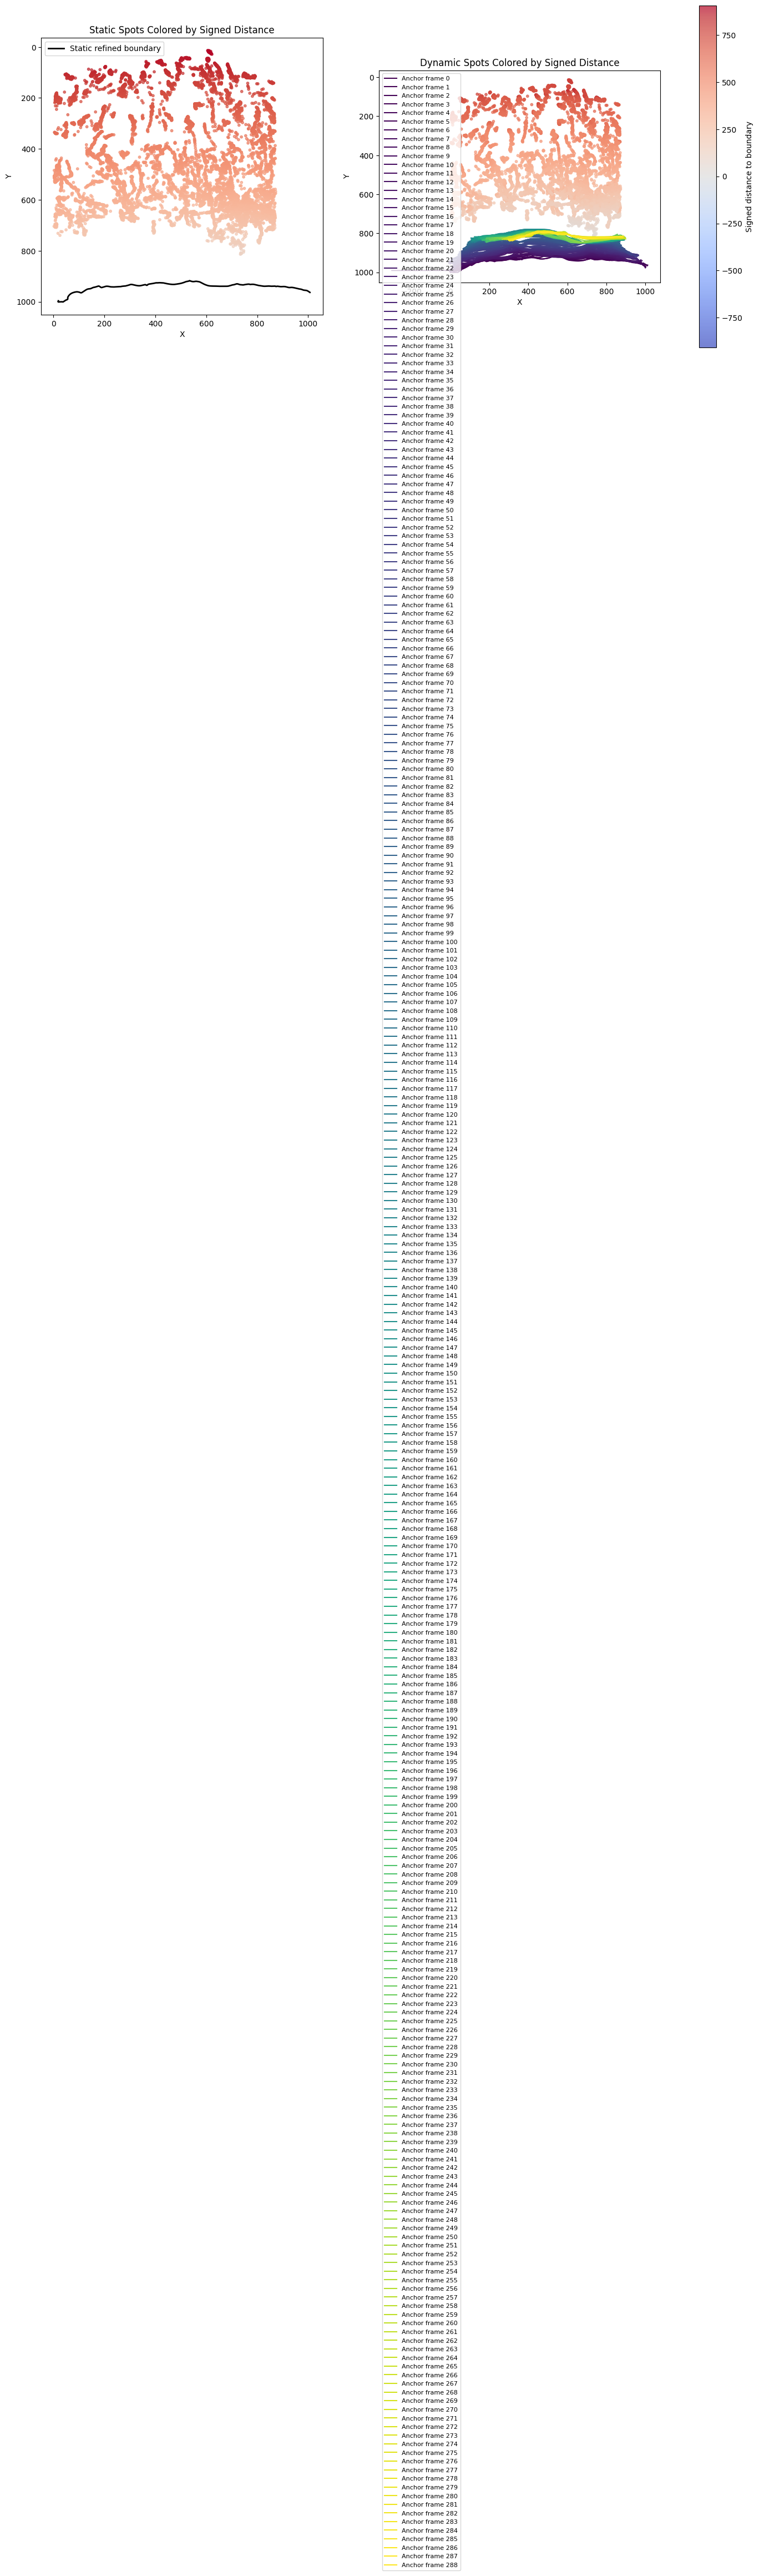

In [ ]:
combined_distances = np.concatenate(
    [
        df_spots["signed_distance_to_boundary"].to_numpy(dtype=float),
        df_spots_dynamic["dynamic_signed_distance_to_boundary"].to_numpy(dtype=float),
    ]
)
color_limit = float(np.nanmax(np.abs(combined_distances)))

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

static_scatter = axes[0].scatter(
    df_spots["X"],
    df_spots["Y"],
    c=df_spots["signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
    vmin=-color_limit,
    vmax=color_limit,
)
axes[0].plot(static_curve[:, 0], static_curve[:, 1], color="black", linewidth=2.0, label="Static refined boundary")
axes[0].set_aspect("equal")
axes[0].invert_yaxis()
axes[0].set_title("Static Spots Colored by Signed Distance")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].legend(loc="best")

dynamic_scatter = axes[1].scatter(
    df_spots_dynamic["X"],
    df_spots_dynamic["Y"],
    c=df_spots_dynamic["dynamic_signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
    vmin=-color_limit,
    vmax=color_limit,
)
dynamic_line_colors = plt.cm.viridis(np.linspace(0, 1, len(dynamic_anchor_frames)))
for line_color, anchor_frame in zip(dynamic_line_colors, dynamic_anchor_frames):
    dynamic_curve = dynamic_anchor_curve_caches[anchor_frame]["curve"]
    axes[1].plot(
        dynamic_curve[:, 0],
        dynamic_curve[:, 1],
        color=line_color,
        linewidth=1.5,
        label=f"Anchor frame {anchor_frame}",
    )
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].set_title("Dynamic Spots Colored by Signed Distance")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].legend(loc="best", fontsize=8)

fig.colorbar(dynamic_scatter, ax=axes, label="Signed distance to boundary")
plt.show()


In [ ]:
n_lowest_dynamic_spots = 20

lowest_dynamic_signed_distance_spots = (
    df_spots_dynamic[
        [
            "Spot ID",
            "Track ID",
            "Frame",
            "dynamic_anchor_frame",
            "X",
            "Y",
            "dynamic_signed_distance_to_boundary",
            "dynamic_boundary_arc_length",
            "dynamic_closest_boundary_x",
            "dynamic_closest_boundary_y"
        ]
    ]
    .sort_values("dynamic_signed_distance_to_boundary", ascending=True)
    .head(n_lowest_dynamic_spots)
    .reset_index(drop=True)
)

lowest_dynamic_signed_distance_spots


,Spot ID,Track ID,Frame,dynamic_anchor_frame,X,Y,dynamic_signed_distance_to_boundary,dynamic_boundary_arc_length,dynamic_closest_boundary_x,dynamic_closest_boundary_y
0,80356,1081,217,217,734.293171,813.843581,24.475556,560.919736,738.562413,837.943922
1,78211,1081,212,212,739.038874,810.502664,27.213382,578.993212,743.619162,837.327822
2,79317,1081,215,215,736.182799,811.524212,27.589518,558.281073,738.464816,839.019192
3,79313,1081,214,214,735.248928,809.448845,30.632640,562.861705,739.095304,839.839041
4,79703,1081,216,216,746.430851,805.582083,31.377191,576.662007,750.391446,836.708306
5,77326,1081,213,213,736.415988,808.326640,33.439286,571.909903,741.538020,841.371316
6,80949,1081,218,218,747.187449,800.137678,35.150911,568.225802,752.177845,834.932541
7,76152,731,210,210,737.824278,795.040090,41.742439,576.048130,742.910763,836.471466
8,123902,1564,287,287,608.201966,762.078385,44.280057,310.843781,600.370343,805.660367
9,123885,1564,288,288,603.240920,760.535845,44.316270,294.778171,598.374540,804.584116
